# Event Timeline

**Family:** Change over time &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Change over time:* Emphasise changing trends, from intraday moves to series spanning decades.

## Design purpose

Places labelled events along a time axis, with stems alternating above and below so labels don't collide. It shows chronology, gaps and the density of events at a glance.

## When to use

- Tell a historical narrative or company milestones
- Show when discrete events happened relative to each other
- Annotate the context behind changes seen in another chart

## Avoid when

- The events have quantitative values to compare (use a chart with a value axis)
- There are dozens of events that would cram together (filter to key ones)

## Alternatives

- Gantt chart (events with duration)
- Annotated line chart

## Example

Key milestones in the history of Python data visualization.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
events = pd.DataFrame([
    ("2003-01-01", "matplotlib\nreleased"),
    ("2006-01-01", "NumPy 1.0"),
    ("2008-01-01", "pandas\nstarted"),
    ("2012-06-01", "seaborn\nfirst commit"),
    ("2013-01-01", "Bokeh\nannounced"),
    ("2014-12-01", "Jupyter\nspun off IPython"),
    ("2015-11-01", "plotly.js\nopen-sourced"),
    ("2016-09-01", "Altair\nreleased"),
    ("2019-07-01", "Panel / HoloViz"),
    ("2021-10-01", "Streamlit 1.0"),
], columns=["date", "event"])
events["date"] = pd.to_datetime(events["date"])
events

,date,event
0,2003-01-01,matplotlib\nreleased
1,2006-01-01,NumPy 1.0
2,2008-01-01,pandas\nstarted
3,2012-06-01,seaborn\nfirst commit
4,2013-01-01,Bokeh\nannounced
5,2014-12-01,Jupyter\nspun off IPython
6,2015-11-01,plotly.js\nopen-sourced
7,2016-09-01,Altair\nreleased
8,2019-07-01,Panel / HoloViz
9,2021-10-01,Streamlit 1.0


### Plot

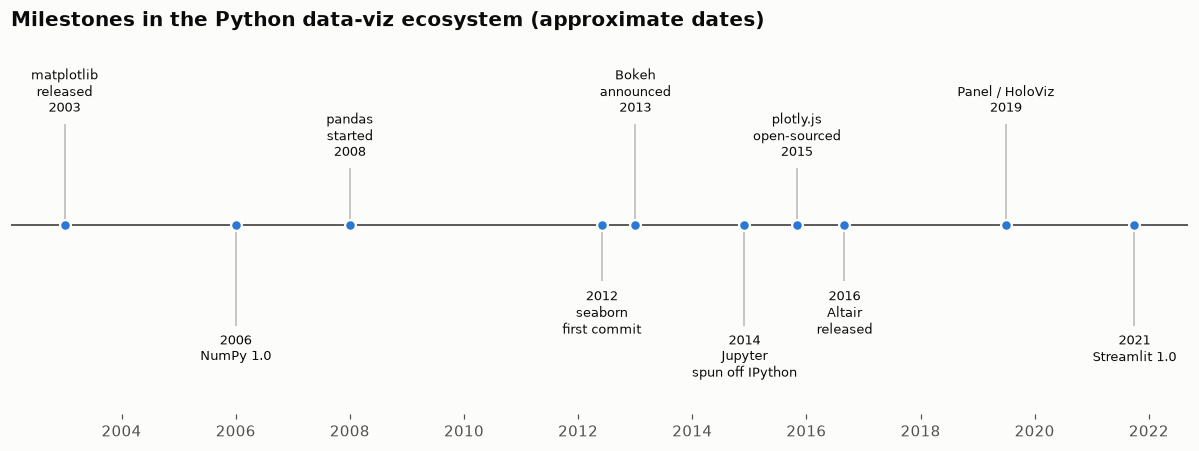

In [3]:
import matplotlib.dates as mdates
levels = np.tile([1.6, -1.6, 0.9, -0.9], len(events))[:len(events)]
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.axhline(0, color="#52514e", linewidth=1.2)
ax.vlines(events["date"], 0, levels, color=GRAY, linewidth=1)
ax.scatter(events["date"], np.zeros(len(events)), s=50, color=PALETTE[0], zorder=3,
           edgecolor="#fcfcfb", linewidth=1.5)
for d, lvl, txt in zip(events["date"], levels, events["event"]):
    ax.text(d, lvl + (0.12 if lvl > 0 else -0.12), f"{txt}\n{d:%Y}" if lvl > 0 else f"{d:%Y}\n{txt}",
            ha="center", va="bottom" if lvl > 0 else "top", fontsize=8.5)
ax.set_ylim(-3, 3)
ax.yaxis.set_visible(False)
for s in ["left", "bottom"]:
    ax.spines[s].set_visible(False)
ax.grid(False)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Milestones in the Python data-viz ecosystem (approximate dates)")
fig.tight_layout()
plt.show()

---
Standalone script: [`event_timeline.py`](event_timeline.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)